# Regression Analysis

This notebook develops regression models to examine how Math and ELA proficiency are associated with chronic absenteeism and school-level student characteristics while accounting for differences across grade levels and years.

The exploratory analysis identified substantial differences in proficiency patterns by subject and grade, as well as overlap among several candidate school-level predictors. These findings are used to guide variable selection and model specification.

## Setup and Load Analysis Data

Import the required libraries, define project paths, and load the analysis-ready dataset created during data integration.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [2]:
PROJECT_ROOT = Path.home() / "Documents" / "Maryland Education Project"
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

In [3]:
analysis_path = PROCESSED_DATA_DIR / "analysis_ready_2023_2025.csv"

# preserve leading zeros in school and district identifiers
df = pd.read_csv(
    analysis_path,
    dtype={
        "lea_id": "string",
        "school_id": "string"
    }
)

df.shape

(22102, 31)

## Prepare Data for Regression
Variables used in the initial regression models are prepared and checked for missing values. The initial models use proficiency as the outcome and subject, grade, and year as categorical predictors. School-level characteristics will be introduced in subsequent models.

In [4]:
regression_cols = [
    "proficient_pct_numeric",
    "subject",
    "grade",
    "year"
]

df[regression_cols].info()

<class 'pandas.DataFrame'>
RangeIndex: 22102 entries, 0 to 22101
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   proficient_pct_numeric  21707 non-null  float64
 1   subject                 22102 non-null  str    
 2   grade                   22102 non-null  int64  
 3   year                    22102 non-null  int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 690.8 KB


In [5]:
# keep observations with complete data for the baseline regression variables
baseline_df = df[regression_cols].dropna().copy()

baseline_df.shape

(21707, 4)

## Baseline Regression Model

The baseline regression model examines differences in proficiency across subject, grade, and year before adding school-level characteristics. ELA, Grade 3, and 2023 are used as the reference categories.

In [6]:
# check categories for each categorical predictor before fitting the model
for col in ["subject", "grade", "year"]:
    print(f"{col}: {sorted(baseline_df[col].unique())}")

subject: ['ELA', 'Math']
grade: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
year: [np.int64(2023), np.int64(2024), np.int64(2025)]


In [7]:
# fit the baseline model using subject, grade, and year as categorical predictors
baseline_model = smf.ols(
    "proficient_pct_numeric ~ C(subject) + C(grade) + C(year)",
    data=baseline_df
).fit()

baseline_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.207
Model:                                OLS   Adj. R-squared:                  0.207
Method:                     Least Squares   F-statistic:                     708.2
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:54   Log-Likelihood:                -96459.
No. Observations:                   21707   AIC:                         1.929e+05
Df Residuals:                       21698   BIC:                         1.930e+05
Df Model:                               8                                         
Covariance Type:                nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             50.5399      0.375    134.944      0.000      49.806      51.274
C(subject)[T.Math]   -18.1715      0.280    -65.003      0.000     -18.719     -17.624
C(grade)[T.4]         -3.5874      0.404     -8.875      0.000      -4.380      -2.795
C(grade)[T.5]         -8.2455      0.405    -20.378      0.000      -9.039      -7.452
C(grade)[T.6]        -11.4853      0.532    -21.606      0.000     -12.527     -10.443
C(grade)[T.7]        -11.9043      0.540    -22.037      0.000     -12.963     -10.846
C(grade)[T.8]        -16.4134      0.540    -30.395      0.000     -17.472     -15.355
C(year)[T.2024]        0.5399      0.342      1.578      0.115      -0.131       1.210
C(year)[T.2025]        2.4638      0.342      7.197      0.000       1.793       3.135
==============================================================================
Omnibus:                     1064.403   Durbin-Watson:                   0.540
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              819.575
Skew:                           0.386   Prob(JB):                    1.08e-178
Kurtosis:                       2.444   Cond. No.                         7.43
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Baseline Model Interpretation

The baseline model explains approximately 20.7% of the variation in proficiency. After accounting for grade and year, Math proficiency is estimated to be lower than ELA proficiency on average.

However, this model assumes that the difference between Math and ELA proficiency is the same across all grade levels. The exploratory analysis showed that the Math–ELA proficiency gap varied substantially by grade, particularly in grades 6–8. A subject-by-grade interaction is therefore examined next.

### Subject-by-Grade Interaction
The baseline model assumes that the difference between Math and ELA proficiency is constant across grades. Because the exploratory analysis showed that this gap varied by grade, an interaction between subject and grade is added to allow the Math–ELA difference to change across grade levels.

In [8]:
# allow the relationship between subject and proficiency to vary by grade
interaction_model = smf.ols(
    "proficient_pct_numeric ~ C(subject) * C(grade) + C(year)",
    data=baseline_df
).fit()

interaction_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.248
Model:                                OLS   Adj. R-squared:                  0.247
Method:                     Least Squares   F-statistic:                     549.5
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:54   Log-Likelihood:                -95888.
No. Observations:                   21707   AIC:                         1.918e+05
Df Residuals:                       21693   BIC:                         1.919e+05
Df Model:                              13                                         
Covariance Type:                nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           45.2188      0.438    103.163      0.000      44.360      46.078
C(subject)[T.Math]                  -7.5272      0.557    -13.512      0.000      -8.619      -6.435
C(grade)[T.4]                        0.5303      0.557      0.952      0.341      -0.561       1.622
C(grade)[T.5]                       -4.5526      0.557     -8.168      0.000      -5.645      -3.460
C(grade)[T.6]                       -1.0314      0.732     -1.408      0.159      -2.467       0.404
C(grade)[T.7]                        0.2510      0.744      0.337      0.736      -1.207       1.709
C(grade)[T.8]                       -2.4304      0.742     -3.276      0.001      -3.885      -0.976
C(year)[T.2024]                      0.5365      0.333      1.610      0.107      -0.117       1.190
C(year)[T.2025]                      2.4670      0.333      7.398      0.000       1.813       3.121
C(subject)[T.Math]:C(grade)[T.4]    -8.2375      0.788    -10.460      0.000      -9.781      -6.694
C(subject)[T.Math]:C(grade)[T.5]    -7.3878      0.788     -9.372      0.000      -8.933      -5.843
C(subject)[T.Math]:C(grade)[T.6]   -20.9097      1.036    -20.191      0.000     -22.940     -18.880
C(subject)[T.Math]:C(grade)[T.7]   -24.3196      1.052    -23.108      0.000     -26.382     -22.257
C(subject)[T.Math]:C(grade)[T.8]   -28.0977      1.052    -26.707      0.000     -30.160     -26.036
==============================================================================
Omnibus:                     1021.427   Durbin-Watson:                   0.502
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              678.033
Skew:                           0.315   Prob(JB):                    5.85e-148
Kurtosis:                       2.407   Cond. No.                         17.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Interaction Model Interpretation

Adding a subject-by-grade interaction increases R² from 0.207 to 0.248 and adjusted R² from 0.207 to 0.247, indicating that allowing the Math–ELA proficiency difference to vary by grade better represents the observed proficiency patterns.

With the interaction included, the Math coefficient no longer represents an overall Math–ELA difference. Instead, because Grade 3 is the reference grade, the Math coefficient indicates that predicted Math proficiency is approximately 7.5 percentage points lower than ELA proficiency in Grade 3 (p < 0.001), holding year constant.

The interaction terms show how the Math–ELA difference changes relative to Grade 3. For example, the Grade 8 Math interaction coefficient is -28.1 (p < 0.001). Combined with the Grade 3 Math coefficient of -7.5, the estimated Math–ELA difference in Grade 8 is approximately -35.6 percentage points. All five subject-by-grade interaction terms are statistically significant (p < 0.001), providing evidence that the Math–ELA difference varies across grades.

The year results remain similar to the baseline model. The estimated difference between 2024 and 2023 is not statistically significant (p = 0.107), while predicted proficiency in 2025 is approximately 2.5 percentage points higher than in 2023 (p < 0.001), holding subject and grade constant.

Since the Math–ELA proficiency difference varies substantially by grade, the subject-by-grade interaction is retained in subsequent models.

These later-grade Math results should be interpreted with consideration of assessment participation. Some students in grades 6–8 may take course-based mathematics assessments rather than the corresponding grade-level Math MCAP, so grade-level Math results may not represent all students enrolled in each grade.

## School Characteristics and Proficiency
This section extends the regression model by adding school-level characteristics to examine their associations with proficiency after accounting for subject, grade, and year.

### Core Regression Model

In [9]:
# convert school-level percentage variables to numeric values for regression
regression_numeric_cols = [
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct"
]

df[regression_numeric_cols] = df[regression_numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

df[regression_numeric_cols].dtypes

chronic_absentee_pct              float64
farms_pct                         float64
students_with_disabilities_pct    float64
dtype: object

In [10]:
core_model_cols = [
    "proficient_pct_numeric",
    "subject",
    "grade",
    "year",
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct"
]

# keep observations with complete data for all core model variables
core_model_df = df[core_model_cols].dropna()

core_model_df.shape

(19530, 7)

In [11]:
# add school characteristics while retaining the subject-by-grade interaction
core_model = smf.ols(
    """proficient_pct_numeric ~ C(subject) * C(grade) + C(year)
       + chronic_absentee_pct
       + farms_pct
       + students_with_disabilities_pct""",
    data=core_model_df
).fit()

core_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.757
Model:                                OLS   Adj. R-squared:                  0.757
Method:                     Least Squares   F-statistic:                     3809.
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:55   Log-Likelihood:                -74860.
No. Observations:                   19530   AIC:                         1.498e+05
Df Residuals:                       19513   BIC:                         1.499e+05
Df Model:                              16                                         
Covariance Type:                nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           83.5385      0.369    226.162      0.000      82.814      84.262
C(subject)[T.Math]                  -7.5814      0.324    -23.373      0.000      -8.217      -6.946
C(grade)[T.4]                        0.6425      0.324      1.981      0.048       0.007       1.278
C(grade)[T.5]                       -4.4978      0.325    -13.844      0.000      -5.135      -3.861
C(grade)[T.6]                        0.2044      0.437      0.468      0.640      -0.652       1.061
C(grade)[T.7]                        0.4659      0.444      1.049      0.294      -0.405       1.337
C(grade)[T.8]                       -1.6240      0.444     -3.660      0.000      -2.494      -0.754
C(year)[T.2024]                     -1.9738      0.194    -10.162      0.000      -2.355      -1.593
C(year)[T.2025]                     -0.4098      0.209     -1.960      0.050      -0.820    2.41e-05
C(subject)[T.Math]:C(grade)[T.4]    -8.4146      0.459    -18.346      0.000      -9.314      -7.516
C(subject)[T.Math]:C(grade)[T.5]    -7.5286      0.459    -16.386      0.000      -8.429      -6.628
C(subject)[T.Math]:C(grade)[T.6]   -20.7319      0.617    -33.625      0.000     -21.940     -19.523
C(subject)[T.Math]:C(grade)[T.7]   -24.3344      0.627    -38.811      0.000     -25.563     -23.105
C(subject)[T.Math]:C(grade)[T.8]   -28.5454      0.628    -45.468      0.000     -29.776     -27.315
chronic_absentee_pct                -0.2793      0.009    -31.210      0.000      -0.297      -0.262
farms_pct                           -0.5922      0.005   -113.610      0.000      -0.602      -0.582
students_with_disabilities_pct       0.1910      0.016     12.226      0.000       0.160       0.222
==============================================================================
Omnibus:                      192.604   Durbin-Watson:                   1.100
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              280.573
Skew:                           0.113   Prob(JB):                     1.19e-61
Kurtosis:                       3.542   Cond. No.                         851.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Initial Core Model Results

The core model explains approximately 75.7% of the variation in proficiency. Chronic absenteeism and FARMS are negatively associated with proficiency after controlling for subject, grade, year, and the other school characteristics.

The adjusted SWD coefficient is positive, despite relationships observed during the exploratory analysis that varied considerably by grade. Because the relationship between SWD percentage and proficiency appeared to differ across grades during EDA, a potential SWD-by-grade interaction is examined next before interpreting the core model as the final specification.

### SWD-by-Grade Interaction
The exploratory analysis suggested that the relationship between SWD percentage and proficiency may differ across grade levels. To examine whether the core model should account for these differences, an interaction between SWD percentage and grade is tested.

In [12]:
# allow the association between SWD percentage and proficiency to vary by grade
swd_interaction_model = smf.ols(
    """proficient_pct_numeric ~ C(subject) * C(grade) + C(year)
       + chronic_absentee_pct
       + farms_pct
       + students_with_disabilities_pct * C(grade)""",
    data=core_model_df
).fit()

swd_interaction_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.758
Model:                                OLS   Adj. R-squared:                  0.757
Method:                     Least Squares   F-statistic:                     2903.
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:56   Log-Likelihood:                -74854.
No. Observations:                   19530   AIC:                         1.498e+05
Df Residuals:                       19508   BIC:                         1.499e+05
Df Model:                              21                                         
Covariance Type:                nonrobust                                         
================================================================================================================
                                                   coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercept                                       83.6722      0.536    155.969      0.000      82.621      84.724
C(subject)[T.Math]                              -7.5814      0.324    -23.376      0.000      -8.217      -6.946
C(grade)[T.4]                                    0.7716      0.693      1.113      0.266      -0.588       2.131
C(grade)[T.5]                                   -5.0264      0.695     -7.235      0.000      -6.388      -3.665
C(grade)[T.6]                                    1.7896      0.952      1.879      0.060      -0.077       3.656
C(grade)[T.7]                                    0.2350      0.959      0.245      0.806      -1.644       2.114
C(grade)[T.8]                                   -2.8710      0.858     -3.347      0.001      -4.552      -1.190
C(year)[T.2024]                                 -1.9721      0.194    -10.150      0.000      -2.353      -1.591
C(year)[T.2025]                                 -0.4099      0.209     -1.960      0.050      -0.820   -6.12e-05
C(subject)[T.Math]:C(grade)[T.4]                -8.4146      0.459    -18.348      0.000      -9.314      -7.516
C(subject)[T.Math]:C(grade)[T.5]                -7.5286      0.459    -16.388      0.000      -8.429      -6.628
C(subject)[T.Math]:C(grade)[T.6]               -20.7319      0.616    -33.630      0.000     -21.940     -19.524
C(subject)[T.Math]:C(grade)[T.7]               -24.3344      0.627    -38.817      0.000     -25.563     -23.106
C(subject)[T.Math]:C(grade)[T.8]               -28.5390      0.628    -45.464      0.000     -29.769     -27.309
chronic_absentee_pct                            -0.2792      0.009    -30.517      0.000      -0.297      -0.261
farms_pct                                       -0.5920      0.005   -113.487      0.000      -0.602      -0.582
students_with_disabilities_pct                   0.1807      0.031      5.843      0.000       0.120       0.241
students_with_disabilities_pct:C(grade)[T.4]    -0.0092      0.044     -0.210      0.833      -0.095       0.076
students_with_disabilities_pct:C(grade)[T.5]     0.0376      0.044      0.860      0.390      -0.048       0.123
students_with_disabilities_pct:C(grade)[T.6]    -0.1250      0.065     -1.926      0.054      -0.252       0.002
students_with_disabilities_pct:C(grade)[T.7]     0.0169      0.064      0.263      0.792      -0.109       0.143
students_with_disabilities_pct:C(grade)[T.8]     0.0935      0.055      1.713      0.087      -0.014       0.200
==============================================================================
Omnibus:                      190.885   Durbin-Watson:                   1.099
Prob(Omnibus):                  0.000   Jarque-Bera (JB)

In [13]:
# test whether adding the SWD-by-grade interactions improves the model
anova_lm(core_model, swd_interaction_model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19513.0,2.441048e+06,0.0,NaN,NaN,NaN
1,19508.0,2.439722e+06,5.0,1326.088182,2.120679,0.059883


#### SWD-by-Grade Interaction Results

Adding the SWD-by-grade interaction produces little change in model fit, with R² increasing from 0.757 to 0.758.

A conventional joint F-test was used to determine whether the five SWD-by-grade interaction terms collectively improve the model. The interaction terms are not jointly statistically significant at the 0.05 level (F = 2.12, p = 0.060).

Therefore, the simpler core model without the SWD-by-grade interaction is retained.

### Contribution of Core School Characteristics

To evaluate whether the core school characteristics improve model fit, the subject, grade, and year model is refit using the same observations as the core model. Using the same sample ensures that differences in model fit are due to the added predictors rather than differences in the observations included in each model.

In [14]:
# refit the subject-grade-year model using the same observations as the core model
comparison_model = smf.ols(
    "proficient_pct_numeric ~ C(subject) * C(grade) + C(year)",
    data=core_model_df
).fit()

# test whether the school-level predictors jointly improve the model
anova_lm(comparison_model, core_model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19516.0,7.404639e+06,0.0,NaN,NaN,NaN
1,19513.0,2.441048e+06,3.0,4.963591e+06,13225.815335,0.0


#### Core Predictor Comparison

Using the same observations for both models, adding chronic absenteeism, FARMS, and SWD percentage substantially improves model fit. The three school-characteristic predictors are jointly statistically significant (F = 13225.82, p < 0.001), and R² increases from approximately 0.25 to 0.76.

This provides evidence that the core school characteristics explain substantial additional variation in proficiency beyond subject, grade, and year.

### Extended Regression Model
The extended regression model adds Multilingual Learner (ML) and Gifted and Talented (GT) percentages to examine whether these additional school characteristics are associated with proficiency after controlling for the variables in the core model.

Because ML and GT percentages have substantially more missing values than the core predictors, the extended model is treated as an additional analysis rather than a replacement for the core model.

In [15]:
# create a complete-case sample for the extended model
extended_model_cols = [
    "proficient_pct_numeric",
    "subject",
    "grade",
    "year",
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct",
    "multilingual_learner_pct",
    "gifted_talented_pct"
]

# convert the additional percentage variables to numeric values
df[["multilingual_learner_pct", "gifted_talented_pct"]] = (
    df[["multilingual_learner_pct", "gifted_talented_pct"]]
    .apply(pd.to_numeric, errors="coerce")
)

extended_model_df = df[extended_model_cols].dropna()

extended_model_df.shape

(7509, 9)

The extended model contains 7,509 complete observations, compared with 19,530 observations in the core model. This substantial reduction is primarily due to missing values in the ML and GT variables. Therefore, the extended model is used as an additional analysis, while the core model remains the primary specification because it retains substantially more observations.

In [16]:
# fit the extended model with ML and GT percentages added
extended_model = smf.ols(
    """proficient_pct_numeric ~ C(subject) * C(grade) + C(year)
       + chronic_absentee_pct
       + farms_pct
       + students_with_disabilities_pct
       + multilingual_learner_pct
       + gifted_talented_pct""",
    data=extended_model_df
).fit()

extended_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.800
Model:                                OLS   Adj. R-squared:                  0.799
Method:                     Least Squares   F-statistic:                     1662.
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:57   Log-Likelihood:                -27862.
No. Observations:                    7509   AIC:                         5.576e+04
Df Residuals:                        7490   BIC:                         5.589e+04
Df Model:                              18                                         
Covariance Type:                nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           91.0045      0.641    141.867      0.000      89.747      92.262
C(subject)[T.Math]                  -7.5256      0.460    -16.351      0.000      -8.428      -6.623
C(grade)[T.4]                        0.4984      0.460      1.084      0.278      -0.403       1.400
C(grade)[T.5]                       -4.4684      0.460     -9.719      0.000      -5.370      -3.567
C(grade)[T.6]                       -2.9849      0.655     -4.557      0.000      -4.269      -1.701
C(grade)[T.7]                       -2.7534      0.667     -4.125      0.000      -4.062      -1.445
C(grade)[T.8]                       -5.4952      0.667     -8.243      0.000      -6.802      -4.188
C(year)[T.2024]                     -1.2842      0.286     -4.492      0.000      -1.845      -0.724
C(year)[T.2025]                      0.4407      0.299      1.476      0.140      -0.145       1.026
C(subject)[T.Math]:C(grade)[T.4]    -8.3753      0.650    -12.878      0.000      -9.650      -7.100
C(subject)[T.Math]:C(grade)[T.5]    -7.0080      0.650    -10.778      0.000      -8.283      -5.733
C(subject)[T.Math]:C(grade)[T.6]   -20.0184      0.894    -22.394      0.000     -21.771     -18.266
C(subject)[T.Math]:C(grade)[T.7]   -26.7199      0.909    -29.387      0.000     -28.502     -24.937
C(subject)[T.Math]:C(grade)[T.8]   -30.6463      0.912    -33.605      0.000     -32.434     -28.859
chronic_absentee_pct                -0.3589      0.016    -22.602      0.000      -0.390      -0.328
farms_pct                           -0.5863      0.009    -67.784      0.000      -0.603      -0.569
students_with_disabilities_pct      -0.0412      0.024     -1.727      0.084      -0.088       0.006
multilingual_learner_pct            -0.1544      0.010    -14.863      0.000      -0.175      -0.134
gifted_talented_pct                  0.0723      0.014      5.207      0.000       0.045       0.100
==============================================================================
Omnibus:                       20.973   Durbin-Watson:                   1.213
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               25.889
Skew:                           0.040   Prob(JB):                     2.39e-06
Kurtosis:                       3.276   Cond. No.                         867.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Initial Extended Model Results

The extended model explains approximately 80.0% of the variation in proficiency. Chronic absenteeism, FARMS, and ML percentages have negative estimated coefficients, while GT percentage has a positive estimated coefficient. The SWD coefficient also changes from positive in the core model to slightly negative in the extended model.

However, the extended model is based on a substantially smaller sample than the core model. Because the two models use different observations, their R² values and coefficient estimates should not be compared directly to determine whether adding ML and GT improves the model. A same-sample comparison is conducted next.

### Same-Sample Comparison

Because the core and extended models use different numbers of observations, their model fit and coefficients cannot be directly compared. To make a fair comparison, the core model is refit using the same 7,509 observations included in the extended model.

In [17]:
# use the extended model's observations to isolate the effect of adding ML and GT
core_same_sample_model = smf.ols(
    """proficient_pct_numeric ~ C(subject) * C(grade) + C(year)
       + chronic_absentee_pct
       + farms_pct
       + students_with_disabilities_pct""",
    data=extended_model_df
).fit()

core_same_sample_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.793
Model:                                OLS   Adj. R-squared:                  0.792
Method:                     Least Squares   F-statistic:                     1791.
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:31:57   Log-Likelihood:                -27990.
No. Observations:                    7509   AIC:                         5.601e+04
Df Residuals:                        7492   BIC:                         5.613e+04
Df Model:                              16                                         
Covariance Type:                nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           90.9773      0.578    157.352      0.000      89.844      92.111
C(subject)[T.Math]                  -7.5256      0.468    -16.077      0.000      -8.443      -6.608
C(grade)[T.4]                        0.4943      0.468      1.057      0.291      -0.423       1.411
C(grade)[T.5]                       -4.4630      0.468     -9.545      0.000      -5.380      -3.546
C(grade)[T.6]                       -1.7327      0.645     -2.686      0.007      -2.997      -0.468
C(grade)[T.7]                       -1.3701      0.656     -2.090      0.037      -2.655      -0.085
C(grade)[T.8]                       -4.1087      0.655     -6.274      0.000      -5.392      -2.825
C(year)[T.2024]                     -1.3739      0.291     -4.729      0.000      -1.943      -0.804
C(year)[T.2025]                      0.4380      0.303      1.447      0.148      -0.155       1.031
C(subject)[T.Math]:C(grade)[T.4]    -8.3753      0.661    -12.662      0.000      -9.672      -7.079
C(subject)[T.Math]:C(grade)[T.5]    -7.0080      0.661    -10.598      0.000      -8.304      -5.712
C(subject)[T.Math]:C(grade)[T.6]   -20.0184      0.909    -22.019      0.000     -21.801     -18.236
C(subject)[T.Math]:C(grade)[T.7]   -26.7199      0.925    -28.895      0.000     -28.533     -24.907
C(subject)[T.Math]:C(grade)[T.8]   -30.6071      0.927    -33.000      0.000     -32.425     -28.789
chronic_absentee_pct                -0.3545      0.016    -22.064      0.000      -0.386      -0.323
farms_pct                           -0.6299      0.008    -75.392      0.000      -0.646      -0.614
students_with_disabilities_pct      -0.0122      0.024     -0.507      0.612      -0.059       0.035
==============================================================================
Omnibus:                       32.792   Durbin-Watson:                   1.194
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               44.897
Skew:                          -0.019   Prob(JB):                     1.78e-10
Kurtosis:                       3.377   Cond. No.                         817.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [18]:
# test whether adding ML and GT jointly improves the model
anova_lm(core_same_sample_model, extended_model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7492.0,760017.506747,0.0,NaN,NaN,NaN
1,7490.0,734587.028739,2.0,25430.478008,129.647185,4.442459e-56


#### Extended Model Comparison

Using the same 7,509 observations, adding ML and GT percentages increases R² from 0.793 to 0.800. A joint F-test indicates that ML and GT collectively improve model fit (F = 129.65, p < 0.001).

Although ML and GT provide additional explanatory information within this sample, including these variables substantially reduces the number of available observations. Therefore, the core model is retained as the primary specification, while the extended model is used as an additional analysis.

## Regression Model Diagnostics

Regression diagnostics are used to evaluate whether the assumptions underlying the regression model are reasonably satisfied. Diagnostics are examined first for the core model and then for the extended model.

### Core Model Diagnostics

#### Linearity and Constant Variance

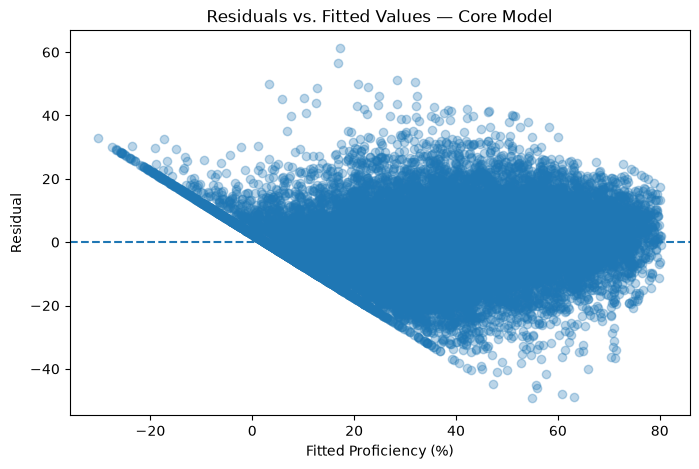

In [19]:
# extract fitted proficiency values and residuals from the core model
fitted_values = core_model.fittedvalues
residuals = core_model.resid

# plot residuals against fitted values to assess linearity and constant variance
plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted Proficiency (%)")
plt.ylabel("Residual")
plt.title("Residuals vs. Fitted Values — Core Model")

plt.show()

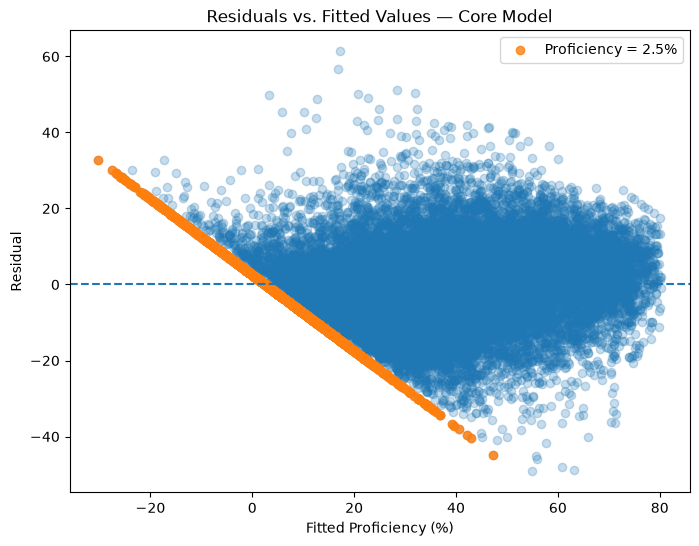

In [20]:
# identify observations with proficiency represented as 2.5%
low_bound_mask = core_model.model.endog == 2.5

plt.figure(figsize=(8, 6))

# plot all observations
plt.scatter(
    core_model.fittedvalues,
    core_model.resid,
    alpha=0.25
)

# highlight observations with proficiency equal to 2.5%
plt.scatter(
    core_model.fittedvalues[low_bound_mask],
    core_model.resid[low_bound_mask],
    alpha=0.8,
    label="Proficiency = 2.5%"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Proficiency (%)")
plt.ylabel("Residual")
plt.title("Residuals vs. Fitted Values — Core Model")
plt.legend()
plt.show()

The residuals do not show a strong curved pattern, suggesting that there is no clear violation of the linearity assumption. However, the spread of the residuals changes across fitted values, suggesting that the constant-variance assumption may not hold.

The prominent diagonal pattern is formed by observations with proficiency values represented as 2.5%. Because these observations all have the same proficiency value, their residuals decrease as their fitted values increase, producing the diagonal line. The plot also shows some fitted proficiency values below 0%, reflecting that OLS does not restrict predictions to the possible 0–100% range.

In [21]:
# test for heteroscedasticity using the Breusch-Pagan test
bp_test = het_breuschpagan(
    core_model.resid,
    core_model.model.exog
)

bp_results = pd.Series(
    bp_test,
    index=["LM Statistic", "LM p-value", "F Statistic", "F p-value"]
)

bp_results

LM Statistic    2.032879e+02
LM p-value      1.715528e-34
F Statistic     1.282796e+01
F p-value       1.096398e-34
dtype: float64

#### Normality of Residuals

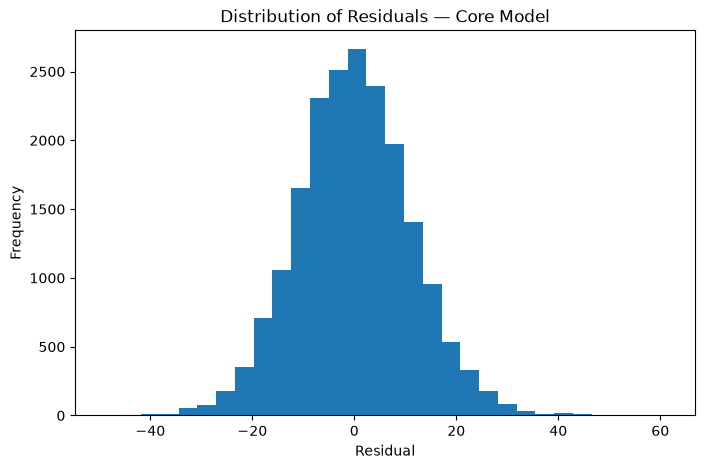

In [22]:
# examine the distribution of the core model residuals
plt.figure(figsize=(8, 5))

plt.hist(core_model.resid, bins=30)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals — Core Model")

plt.show()

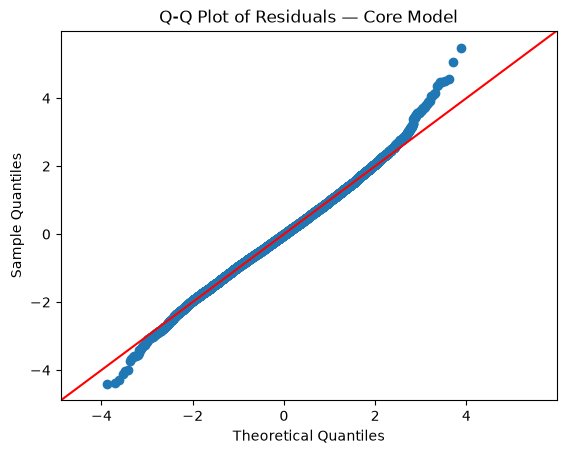

In [23]:
# compare residuals with a normal distribution
sm.qqplot(core_model.resid, line="45", fit=True)

plt.title("Q-Q Plot of Residuals — Core Model")
plt.show()

The residual histogram is approximately bell-shaped and centered near zero. The Q–Q plot shows that the residuals follow the theoretical normal distribution reasonably well through the center of the distribution, with departures in the tails.

Overall, the residuals are approximately normal but show some deviations from normality in the tails.

#### Independence of Errors

The regression data contain repeated observations from the same schools across grades, subjects, and years. Therefore, errors for observations from the same school may be correlated because they can share unmeasured school-level characteristics.

In [41]:
# check whether school IDs are reused across districts
df.loc[core_model_df.index].groupby("school_id")["lea_id"].nunique().loc[lambda x: x > 1]

# school IDs are reused across districts, so both LEA and school IDs are needed
# to uniquely identify schools when calculating clustered standard errors

school_id
0051    2
0075    2
0101    7
0102    5
0103    3
       ..
1604    2
1802    2
2102    2
2107    2
2142    2
Name: lea_id, Length: 199, dtype: int64

In [24]:
# identify schools using both district and school IDs
core_school_groups = (
    df.loc[core_model_df.index, ["lea_id", "school_id"]]
    .astype(str)
    .agg("_".join, axis=1)
)

school_counts = core_school_groups.value_counts()
school_counts.describe()

count    1106.000000
mean       17.658228
std         3.974217
min         1.000000
25%        18.000000
50%        18.000000
75%        18.000000
max        36.000000
Name: count, dtype: float64

In [25]:
# number of unique schools represented in the core model
len(school_counts)

1106

The core model contains 1,106 schools, with individual schools contributing multiple observations across grades, subjects, and years. Because observations from the same school may share unmeasured characteristics, the assumption that all regression errors are independent may not be reasonable.

To account for this data structure, the final regression inference will use standard errors clustered by school. Clustered standard errors allow errors to be correlated within schools while treating different schools as independent clusters. They also provide inference that is robust to heteroscedasticity.   

reference: https://doi.org/10.1016/j.jeconom.2022.04.001  
reference: https://doi.org/10.3368/jhr.50.2.317

#### Multicollinearity

Variance inflation factors (VIFs) are used to assess multicollinearity among the continuous school-characteristic predictors in the core model. High VIF values would indicate that a predictor can be closely explained by the other predictors, which can make its individual coefficient more difficult to estimate precisely.

In [26]:
# calculate VIFs for the continuous school-characteristic predictors
core_vif_cols = [
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct"
]

# create predictor matrix and add an intercept
X_core_vif = add_constant(core_model_df[core_vif_cols])

# calculate VIF for each predictor
core_vif = pd.DataFrame({
    "Variable": X_core_vif.columns,
    "VIF": [
        variance_inflation_factor(X_core_vif.values, i)
        for i in range(X_core_vif.shape[1])
    ]
})

core_vif

,Variable,VIF
0,const,1.000000
1,chronic_absentee_pct,2.090452
2,farms_pct,2.074289
3,students_with_disabilities_pct,1.033743


The VIF values for chronic absenteeism, FARMS, and SWD percentage are all below 2.1, indicating no concerning multicollinearity among the continuous school-characteristic predictors in the core model.

#### Influential Observations

Cook's distance is used to identify observations that may have a relatively large influence on the fitted regression model. The commonly used threshold of \(4/n\) is used as a guideline for identifying observations that may warrant further examination.

In [27]:
# calculate Cook's distance for the core model
core_influence = core_model.get_influence()
core_cooks_d = core_influence.cooks_distance[0]

# common reference threshold
core_cooks_threshold = 4 / len(core_model_df)

core_cooks_threshold

0.0002048131080389145

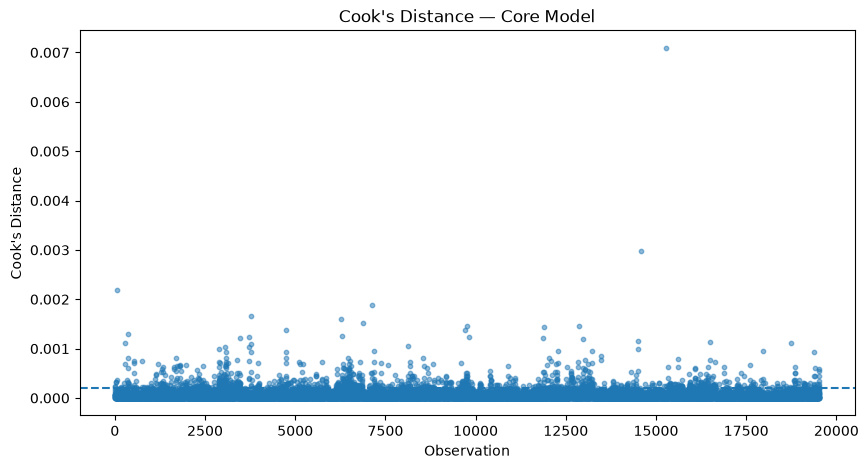

In [28]:
# plot Cook's distance for each observation and the 4/n threshold
plt.figure(figsize=(10, 5))

plt.scatter(
    np.arange(len(core_cooks_d)),
    core_cooks_d,
    s=10,
    alpha=0.5
)

plt.axhline(
    y=core_cooks_threshold,
    linestyle="--"
)

plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance — Core Model")

plt.show()

In [29]:
# summarize potentially influential observations
print("Threshold:", core_cooks_threshold)
print("Observations above threshold:", (core_cooks_d > core_cooks_threshold).sum())
print("Maximum Cook's distance:", core_cooks_d.max())

Threshold: 0.0002048131080389145
Observations above threshold: 967
Maximum Cook's distance: 0.007090810472922207


Using the \(4/n\) guideline, 967 observations exceed the reference threshold. However, with the large core-model sample of 19,530 observations, the \(4/n\) threshold is very small. The Cook's distance plot shows that most observations have values close to zero, and the maximum Cook's distance is approximately 0.007.

Therefore, the diagnostic does not suggest that the model results are being driven by a single highly influential observation. Observations are not removed solely because they exceed the \(4/n\) guideline.

### Extended Model Diagnostics
The same regression diagnostics are examined for the extended model to determine whether it shows similar assumption violations or other potential concerns.

#### Linearity and Constant Variance

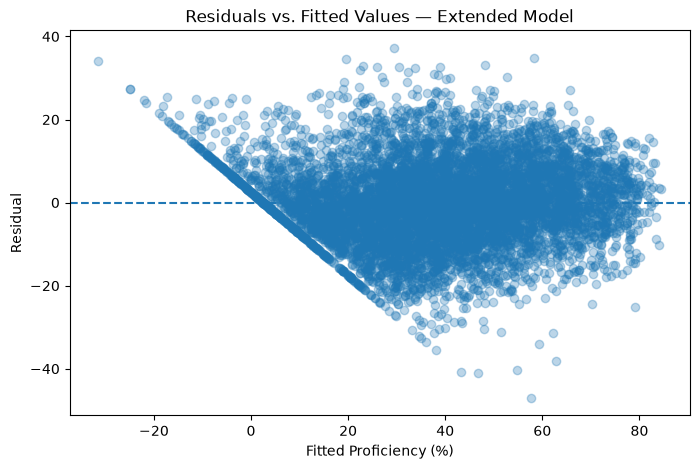

In [30]:
# plot residuals against fitted values to assess linearity and constant variance
full_fitted = extended_model.fittedvalues
full_residuals = extended_model.resid

plt.figure(figsize=(8, 5))

plt.scatter(
    full_fitted,
    full_residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted Proficiency (%)")
plt.ylabel("Residual")
plt.title("Residuals vs. Fitted Values — Extended Model")

plt.show()

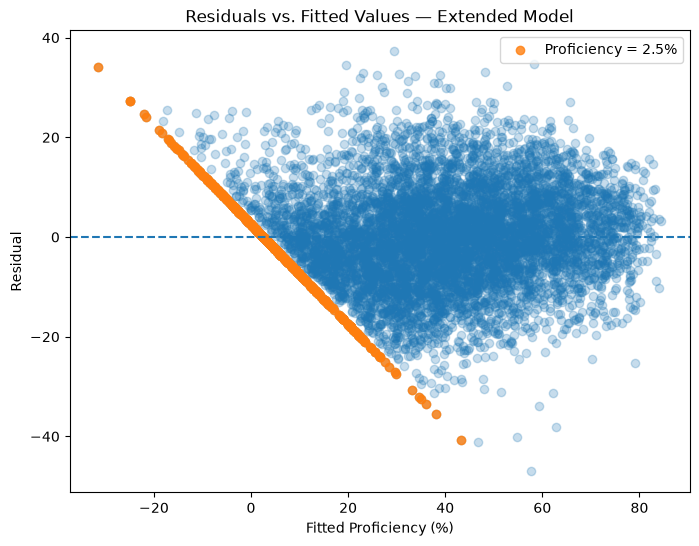

In [31]:
# identify observations with proficiency represented as 2.5%
low_bound_mask_extended = extended_model.model.endog == 2.5

plt.figure(figsize=(8, 6))

# plot all observations
plt.scatter(
    extended_model.fittedvalues,
    extended_model.resid,
    alpha=0.25
)

# highlight observations with proficiency equal to 2.5%
plt.scatter(
    extended_model.fittedvalues[low_bound_mask_extended],
    extended_model.resid[low_bound_mask_extended],
    alpha=0.8,
    label="Proficiency = 2.5%"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Fitted Proficiency (%)")
plt.ylabel("Residual")
plt.title("Residuals vs. Fitted Values — Extended Model")
plt.legend()
plt.show()

The extended-model residual plot shows a pattern similar to the core model. There is no strong curved pattern, but the spread of the residuals varies across fitted values, again suggesting that the constant-variance assumption may not hold.

As in the core model, the diagonal pattern is formed by observations with proficiency values represented as 2.5%. Some fitted proficiency values also fall below 0%, reflecting the same limitation of using OLS with a bounded outcome.

In [32]:
# test for heteroscedasticity using the Breusch-Pagan test
bp_test_full = het_breuschpagan(
    extended_model.resid,
    extended_model.model.exog
)

pd.Series(
    bp_test_full,
    index=["LM Statistic", "LM p-value", "F Statistic", "F p-value"]
)

LM Statistic    1.452965e+02
LM p-value      6.073212e-22
F Statistic     8.210471e+00
F p-value       3.542167e-22
dtype: float64

The Breusch–Pagan test is statistically significant (p < 0.001), providing evidence of heteroscedasticity in the extended model. Therefore, the constant-variance assumption is not satisfied.

#### Normality of Residuals

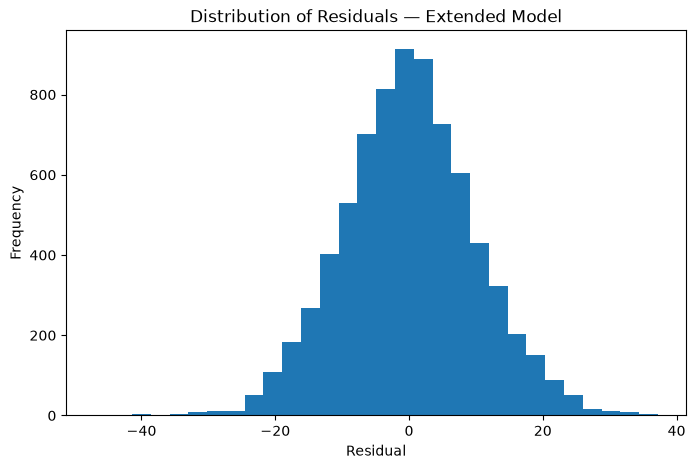

In [33]:
# examine the distribution of extended model residuals
plt.figure(figsize=(8, 5))

plt.hist(full_residuals, bins=30)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals — Extended Model")

plt.show()

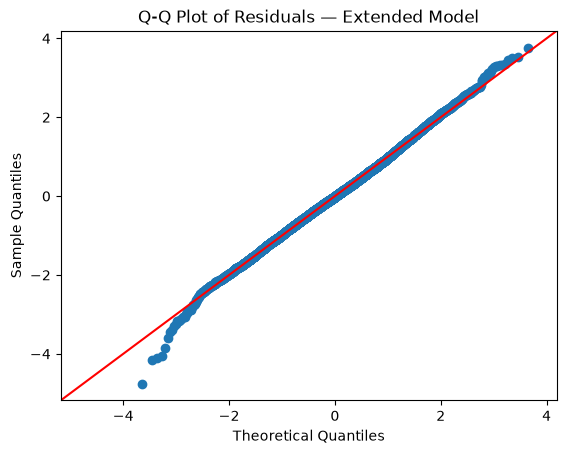

In [34]:
# compare residual quantiles with theoretical normal quantiles
sm.qqplot(
    full_residuals,
    line="45",
    fit=True
)

plt.title("Q-Q Plot of Residuals — Extended Model")
plt.show()

The residual histogram is approximately bell-shaped and centered near zero. The Q–Q plot follows the theoretical normal distribution reasonably well through the center, with some departures in the tails.

Overall, the extended-model residuals are approximately normal but show some deviations from normality in the tails.

#### Independence of Errors

In [35]:
# identify schools using both district and school IDs
extended_school_groups = (
    df.loc[extended_model_df.index, ["lea_id", "school_id"]]
    .astype(str)
    .agg("_".join, axis=1)
)

len(extended_school_groups.unique())

506

The extended model contains observations from 506 schools, with schools contributing repeated observations across grades, subjects, and years. As with the core model, errors from observations within the same school may therefore be correlated. School-clustered standard errors will be used for the final extended-model inference.

#### Multicollinearity

In [36]:
# school-characteristic predictors included in the extended model
extended_vif_cols = [
    "chronic_absentee_pct",
    "farms_pct",
    "students_with_disabilities_pct",
    "multilingual_learner_pct",
    "gifted_talented_pct"
]

# create predictor matrix and add an intercept
X_extended_vif = add_constant(
    extended_model_df[extended_vif_cols]
)

# calculate VIF for each predictor
extended_vif = pd.DataFrame({
    "Variable": X_extended_vif.columns,
    "VIF": [
        variance_inflation_factor(X_extended_vif.values, i)
        for i in range(X_extended_vif.shape[1])
    ]
})

extended_vif

,Variable,VIF
0,const,1.000000
1,chronic_absentee_pct,1.948242
2,farms_pct,2.111153
3,students_with_disabilities_pct,1.041559
4,multilingual_learner_pct,1.166169
5,gifted_talented_pct,1.087006


The VIF values for the school-characteristic predictors are all below 2.2, indicating no concerning multicollinearity among the continuous predictors in the extended model.

#### Influential Observations

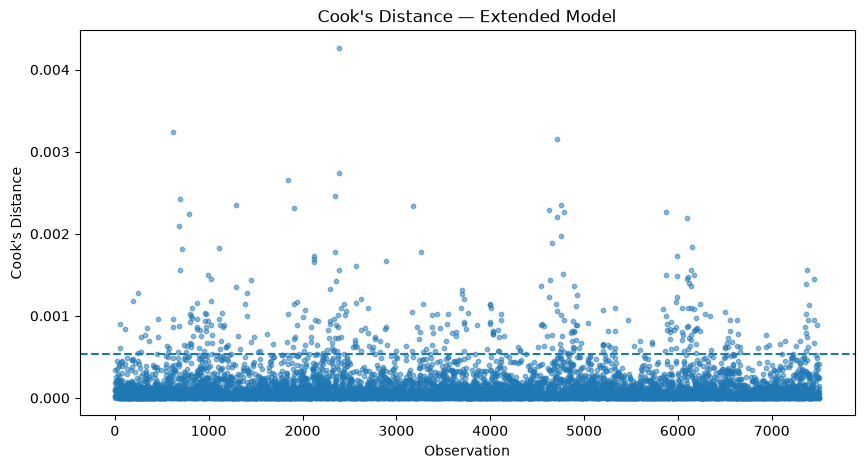

Threshold: 0.0005326941004128379
Observations above threshold: 384
Maximum Cook's distance: 0.0042630429266738365


In [37]:
# calculate Cook's distance for each observation
extended_influence = extended_model.get_influence()
extended_cooks_d = extended_influence.cooks_distance[0]

# common reference threshold
extended_cooks_threshold = 4 / len(extended_model_df)

# plot Cook's distance
plt.figure(figsize=(10, 5))

plt.scatter(
    np.arange(len(extended_cooks_d)),
    extended_cooks_d,
    s=10,
    alpha=0.5
)

plt.axhline(
    y=extended_cooks_threshold,
    linestyle="--"
)

plt.xlabel("Observation")
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance — Extended Model")

plt.show()

# summarize potentially influential observations
print("Threshold:", extended_cooks_threshold)
print(
    "Observations above threshold:",
    (extended_cooks_d > extended_cooks_threshold).sum()
)
print("Maximum Cook's distance:", extended_cooks_d.max())

Using the \(4/n\) guideline, 384 observations exceed the reference threshold. However, the threshold is small given the extended-model sample of 7,509 observations. Most Cook's distance values remain close to zero, and the maximum Cook's distance is approximately 0.004.

As with the core model, the diagnostic does not suggest that the results are being driven by a single highly influential observation. Observations are not removed solely because they exceed the \(4/n\) guideline.

## Final Regression Inference

The diagnostic analysis identified heteroscedasticity and repeated observations within schools. Therefore, the final regression results use standard errors clustered by school. This approach allows for heteroscedasticity and correlation among errors within the same school while retaining the original OLS coefficient estimates.

### Core Model with School-Clustered Standard Errors

The core model is the primary regression specification because it retains substantially more observations than the extended model. Standard errors are clustered across the 1,106 schools represented in the core-model sample.

In [39]:
# calculate standard errors clustered by school
core_model_clustered = core_model.get_robustcov_results(
    cov_type="cluster",
    groups=core_school_groups
)

core_model_clustered.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.757
Model:                                OLS   Adj. R-squared:                  0.757
Method:                     Least Squares   F-statistic:                     1138.
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:32:04   Log-Likelihood:                -74860.
No. Observations:                   19530   AIC:                         1.498e+05
Df Residuals:                       19513   BIC:                         1.499e+05
Df Model:                              16                                         
Covariance Type:                  cluster                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           83.5385      0.823    101.443      0.000      81.923      85.154
C(subject)[T.Math]                  -7.5814      0.233    -32.550      0.000      -8.038      -7.124
C(grade)[T.4]                        0.6425      0.237      2.714      0.007       0.178       1.107
C(grade)[T.5]                       -4.4978      0.280    -16.043      0.000      -5.048      -3.948
C(grade)[T.6]                        0.2044      0.564      0.362      0.717      -0.902       1.311
C(grade)[T.7]                        0.4659      0.565      0.824      0.410      -0.643       1.575
C(grade)[T.8]                       -1.6240      0.581     -2.795      0.005      -2.764      -0.484
C(year)[T.2024]                     -1.9738      0.220     -8.987      0.000      -2.405      -1.543
C(year)[T.2025]                     -0.4098      0.274     -1.497      0.135      -0.947       0.127
C(subject)[T.Math]:C(grade)[T.4]    -8.4146      0.230    -36.650      0.000      -8.865      -7.964
C(subject)[T.Math]:C(grade)[T.5]    -7.5286      0.256    -29.358      0.000      -8.032      -7.025
C(subject)[T.Math]:C(grade)[T.6]   -20.7319      0.534    -38.811      0.000     -21.780     -19.684
C(subject)[T.Math]:C(grade)[T.7]   -24.3344      0.688    -35.365      0.000     -25.685     -22.984
C(subject)[T.Math]:C(grade)[T.8]   -28.5454      0.876    -32.569      0.000     -30.265     -26.826
chronic_absentee_pct                -0.2793      0.023    -12.146      0.000      -0.324      -0.234
farms_pct                           -0.5922      0.014    -43.836      0.000      -0.619      -0.566
students_with_disabilities_pct       0.1910      0.045      4.213      0.000       0.102       0.280
==============================================================================
Omnibus:                      192.604   Durbin-Watson:                   1.100
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              280.573
Skew:                           0.113   Prob(JB):                     1.19e-61
Kurtosis:                       3.542   Cond. No.                         851.
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)
"""

### Extended Model with School-Clustered Standard Errors

The extended model is also evaluated using school-clustered standard errors. This model is based on 7,509 observations from 506 schools because of the greater missingness in the ML and GT variables.

In [40]:
# calculate standard errors clustered by school
extended_model_clustered = extended_model.get_robustcov_results(
    cov_type="cluster",
    groups=extended_school_groups
)

extended_model_clustered.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     proficient_pct_numeric   R-squared:                       0.800
Model:                                OLS   Adj. R-squared:                  0.799
Method:                     Least Squares   F-statistic:                     566.3
Date:                    Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                            11:32:04   Log-Likelihood:                -27862.
No. Observations:                    7509   AIC:                         5.576e+04
Df Residuals:                        7490   BIC:                         5.589e+04
Df Model:                              18                                         
Covariance Type:                  cluster                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           91.0045      1.316     69.140      0.000      88.419      93.590
C(subject)[T.Math]                  -7.5256      0.337    -22.307      0.000      -8.188      -6.863
C(grade)[T.4]                        0.4984      0.373      1.337      0.182      -0.234       1.231
C(grade)[T.5]                       -4.4684      0.407    -10.970      0.000      -5.269      -3.668
C(grade)[T.6]                       -2.9849      0.982     -3.040      0.002      -4.914      -1.056
C(grade)[T.7]                       -2.7534      0.984     -2.800      0.005      -4.686      -0.821
C(grade)[T.8]                       -5.4952      0.973     -5.649      0.000      -7.407      -3.584
C(year)[T.2024]                     -1.2842      0.368     -3.491      0.001      -2.007      -0.561
C(year)[T.2025]                      0.4407      0.425      1.037      0.300      -0.394       1.276
C(subject)[T.Math]:C(grade)[T.4]    -8.3753      0.344    -24.323      0.000      -9.052      -7.699
C(subject)[T.Math]:C(grade)[T.5]    -7.0080      0.379    -18.476      0.000      -7.753      -6.263
C(subject)[T.Math]:C(grade)[T.6]   -20.0184      0.716    -27.953      0.000     -21.425     -18.611
C(subject)[T.Math]:C(grade)[T.7]   -26.7199      0.992    -26.928      0.000     -28.669     -24.770
C(subject)[T.Math]:C(grade)[T.8]   -30.6463      1.196    -25.627      0.000     -32.996     -28.297
chronic_absentee_pct                -0.3589      0.038     -9.478      0.000      -0.433      -0.284
farms_pct                           -0.5863      0.023    -25.969      0.000      -0.631      -0.542
students_with_disabilities_pct      -0.0412      0.060     -0.685      0.494      -0.159       0.077
multilingual_learner_pct            -0.1544      0.029     -5.286      0.000      -0.212      -0.097
gifted_talented_pct                  0.0723      0.041      1.763      0.078      -0.008       0.153
==============================================================================
Omnibus:                       20.973   Durbin-Watson:                   1.213
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               25.889
Skew:                           0.040   Prob(JB):                     2.39e-06
Kurtosis:                       3.276   Cond. No.                         867.
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)
"""

## Key Regression Findings

### Core Model Findings

After accounting for subject, grade, year, and the other school characteristics in the model, chronic absenteeism and FARMS percentage are both negatively associated with proficiency.

The chronic absenteeism coefficient is -0.279, meaning that a 10-percentage-point higher chronic absenteeism rate is associated with approximately 2.8 percentage points lower proficiency, holding the other variables in the model constant (p < 0.001).

The FARMS coefficient is -0.592, meaning that a 10-percentage-point higher FARMS rate is associated with approximately 5.9 percentage points lower proficiency, holding the other variables constant (p < 0.001).

SWD percentage has a positive coefficient of 0.191 in the core model. A 10-percentage-point higher SWD percentage is associated with approximately 1.9 percentage points higher proficiency after adjustment for the other variables in the model (p < 0.001). This adjusted relationship should be interpreted cautiously because the exploratory analysis showed that the relationship between SWD percentage and proficiency varied across grades, and the coefficient was sensitive to the sample used in the extended analysis.

The subject-by-grade interaction also remains statistically significant across grades, supporting the earlier finding that the Math–ELA proficiency difference is not constant across grade levels. The estimated Math–ELA gap becomes substantially larger in the later grades, particularly grades 6–8.

These later-grade Math results should be interpreted with consideration of assessment participation. Some students in grades 6–8 may take course-based mathematics assessments rather than the corresponding grade-level Math MCAP, so grade-level Math results may not represent all students enrolled in the grade.

### Extended Model Findings
The extended model provides additional evidence about ML and GT percentages but is based on a smaller sample of 7,509 observations from 506 schools.

Using school-clustered standard errors, chronic absenteeism and FARMS remain negatively associated with proficiency (p < 0.001). ML percentage is also negatively associated with proficiency: a 10-percentage-point higher ML percentage is associated with approximately 1.5 percentage points lower proficiency, holding the other variables constant (p < 0.001).

In the extended model, SWD percentage and GT percentage are not statistically significant at the 0.05 level. Therefore, the extended model does not provide sufficient evidence of an adjusted association between these variables and proficiency within this smaller sample.

Because the extended model excludes substantially more observations due to missing ML and GT data, it is treated as an additional analysis rather than replacing the core model.

### Overall Takeaway

Across the regression analyses, chronic absenteeism and FARMS percentage show the most consistent negative associations with proficiency. The results also reinforce that Math and ELA proficiency patterns differ substantially across grade levels. The extended analysis suggests an additional negative association with ML percentage, although its smaller sample limits how broadly those results can be compared with the primary core model.

These results describe adjusted associations among school-level characteristics and proficiency and should not be interpreted as evidence that any of these characteristics cause differences in student performance.

## Limitations

This analysis is observational and uses aggregated school-level data rather than individual student records. The regression results therefore describe associations between school-level characteristics and proficiency and should not be interpreted as causal relationships or as relationships that necessarily hold at the individual-student level.

Some MCAP proficiency results are reported as ranges or suppressed values. Values reported as 5% or less were represented as 2.5%, values reported as 95% or greater were represented as 97.5%, and fully suppressed values were treated as missing. These approximations allow the results to be included in the analysis but introduce some uncertainty, particularly where low-bounded proficiency values are common.

The grade-level Math results for grades 6–8 do not necessarily represent all students enrolled in those grades. Some students in grades 6–8 may take course-based mathematics assessments rather than the corresponding grade-level Math MCAP, so comparisons between Math and ELA in these grades should be interpreted cautiously.

Missing ML and GT data substantially reduce the sample available for the extended regression model. The core model includes 19,530 observations from 1,106 schools, while the extended model includes 7,509 observations from 506 schools. As a result, differences between the core and extended models may partly reflect differences in the schools and observations represented in each sample.

Proficiency is also a bounded percentage outcome, while OLS regression does not restrict fitted values to the 0–100% range. Some fitted values therefore fall outside the possible range. Residual diagnostics also identified heteroscedasticity and potential within-school dependence; school-clustered standard errors were used for the final statistical inference to account for these issues.